# Optional: Do the carbon atoms tell the same story? Read the carbon spectra yourself

You'll check the notebook 01 peptides again, this time through their carbon atoms.

Hydrogen NMR (1H) shows the protons; carbon NMR (13C) shows the carbon skeleton. In 13C, read which
bands are there, not their size: carbons without hydrogens (such as C=O) give weak signals in quick
runs.

Time: about 30 minutes. Same samples as notebook 01, in 98% acid.

Data: Petkowski, M. D. Seager, Bains and S. Seager, Zenodo [10.5281/zenodo.11223995](https://doi.org/10.5281/zenodo.11223995), CC BY 4.0. Paper: *Scientific Reports* 14, 17083 (2024).

In [1]:
# Setup. In Colab this first installs the training package (about 30 seconds).
import importlib.util, os
if importlib.util.find_spec("nmrtrain") is None:
    %pip install -q "nmrtrain @ git+https://github.com/Rakiura-Inc/morning-star-nmr@main"
import matplotlib.pyplot as plt
import nmrtrain as nt

NOTEBOOK = "notebooks/05_read_a_13c_series.ipynb"
MODE = nt.portal.connect(NOTEBOOK)

Offline mode: progress is kept in handin/rakiura_progress.json.


**Your turn**

Predict where each kind of carbon appears, in ppm, and enter it in the next cell:

* the carbonyl (C=O)
* the alpha carbon (the backbone carbon next to N)
* the Ala-Ala methyl (CH3)

In [2]:
MY_PREDICTION = {
    "carbonyl_ppm": ...,   # C=O
    "alpha_ppm": ...,      # the backbone carbon next to N
    "methyl_ppm": ...,     # Ala-Ala's CH3
}
nt.record.predict("c13", MY_PREDICTION)

Fill in at least one prediction above (replace the ...), then run this cell again.


In [3]:
if nt.record.revealed("c13"):
    nt.checks.check_prediction(MY_PREDICTION, {
        "carbonyl_ppm": {"label": "carbonyl", "band": [168, 180]},
        "alpha_ppm": {"label": "alpha carbon", "band": [40, 55]},
        "methyl_ppm": {"label": "methyl", "band": [12, 20]}}).show("Your predictions")

Make your prediction in the cell above first.


## Load and stack

AA 13C 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
GG 13C 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
Checks on Ala-Ala in 98% acid: 6 passed, 0 flagged
  nothing to flag
Checks on Gly-Gly in 98% acid: 6 passed, 0 flagged
  nothing to flag


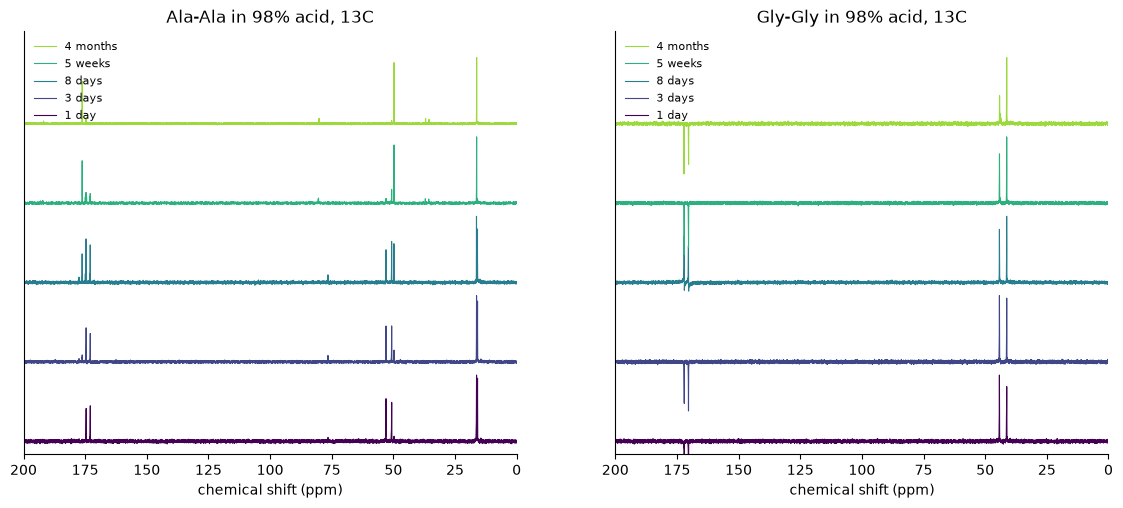

In [4]:
c13 = {pep: nt.load_series("11223995", pep, acid="K", nucleus="13C") for pep in ("AA", "GG")}
fig_13c, axes = plt.subplots(1, 2, figsize=(14, 5.5))
traps = {}
for ax, (pep, ser) in zip(axes, c13.items()):
    nt.plot.stack(ser, 0, 200, norm=(5, 200), ax=ax, title=f"{nt.io.NAMES[pep]} in 98% acid, 13C")
    traps[pep] = nt.checks.run_traps(ser)
plt.show()

### Trap: missing carbonyls

Look at Gly-Gly near 170 ppm: its carbonyls show in only one spectrum. A band missing from a quick
13C run is not evidence that the carbon is gone.

In [5]:
for s in c13["GG"]:
    seen = [p["ppm"] for p in nt.peaks.pick(s, 160, 185, 0.05, group_ppm=0.5, ref=(5, 200))]
    print(f"Gly-Gly {s.time_label:9s} carbonyl bands: {seen or 'none seen'}")

Gly-Gly 1 day     carbonyl bands: none seen
Gly-Gly 3 days    carbonyl bands: none seen
Gly-Gly 8 days    carbonyl bands: [172.116, 170.348]
Gly-Gly 5 weeks   carbonyl bands: none seen
Gly-Gly 4 months  carbonyl bands: none seen


## Compare first and last

**Your turn**

The next cell lists the peaks in the first and last spectrum of each peptide. `MIN_HEIGHT` sets
the smallest peak it lists. Then fill in `MY_VERDICT` for Ala-Ala, using 13C ppm values:

* `call`: `"survives"`, `"degrades"` or `"unsure"`
* `lost_ppm`: bands gone by the last time point
* `new_ppm`: bands that appear by the last time point
* `kept_ppm`: bands present at both times
* `confidence`: `"low"`, `"medium"` or `"high"`

In [6]:
MIN_HEIGHT = 0.05
my_peaks = {pep: {s.time: nt.peaks.pick(s, 5, 200, MIN_HEIGHT, group_ppm=0.5) for s in (ser[0], ser[-1])}
            for pep, ser in c13.items()}
for pep, d in my_peaks.items():
    for t, pk in d.items():
        print(pep, f"{t:7s}", [round(p["ppm"], 1) for p in pk])

MY_VERDICT = {"call": "", "lost_ppm": [], "new_ppm": [], "kept_ppm": [], "confidence": ""}

AA 1day    [174.6, 172.9, 76.5, 53.0, 50.7, 49.8, 16.1]
AA 4Month  [176.2, 174.6, 80.1, 49.8, 36.9, 35.6, 16.2]
GG 1day    [44.2, 41.3]
GG 4Month  [44.1, 41.3]


In [7]:
feedback = nt.checks.Report()
if nt.record.revealed("c13"):
    key = nt.answers.load("c13_series")
    c = nt.answers.case(key, "AA")
    feedback = nt.checks.check_verdict(MY_VERDICT, c).show("Your Ala-Ala verdict")

Make your prediction in the cell above first.


## Hand-in

The next cell saves your 13C stacks and `verdict.json` in `handin/`. Nothing is sent for review
until you run `nt.portal.submit()`.

In [8]:
record = nt.record.handin("c13-verdict", figures={"stack_13C": fig_13c},
                          verdict={"verdict": MY_VERDICT, "feedback": [str(f) for f in feedback]},
                          numbers={"AA_call_13C": MY_VERDICT["call"] or "blank"},
                          question="c13", traps=nt.checks.traps_flagged(*traps.values()))
# nt.portal.submit()

rakiura: c13-verdict done, 1 figure(s), 5 number(s) (offline log)
Saved for your hand-in:
   handin/c13-verdict/stack_13C.png
   handin/c13-verdict/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.
